# ИДЗ №1. Эмпирический и теоретический анализ алгоритмов сортировки

**Студент:** *Макеров Фёдор Михайлович*  
**Группа:** *Б06-505*  
**Вариант:** Stupid Sort, Insertion Sort, QuickSort (разбиение Хоара).

> Этот ноутбук составлен как обучающий отчёт. Перед сдачей выполни **полный эксперимент**, заполни свои данные и напиши выводы по **реальным** замерам. Не оставляй учебные результаты в качестве финального исследования.

**Цели:** проверить корректность сортировок, сравнить время на пяти распределениях, показать графики с погрешностями, оценить закон роста по Log-Log и сопоставить измерения с теорией.

## 1. Что мы исследуем

**Массив** — список значений: `[3, 1, 2]`. Сортировка превращает его в `[1, 2, 3]`.

- **Stupid Sort:** если два соседних элемента стоят неправильно, меняем местами и возвращаемся в начало. Худшее время $O(N^3)$, лучший случай $O(N)$.
- **Insertion Sort:** вставляем каждый следующий элемент в отсортированную левую часть. Худшее время $O(N^2)$, лучший случай $O(N)$.
- **QuickSort (Hoare):** выбираем опорное значение, разделяем массив на части и сортируем их рекурсивно. Среднее время $O(N\log N)$, худшее $O(N^2)$.

**Особенность варианта:** на сайте курса ФБМФ МФТИ Stupid Sort описана как возврат в начало после обмена и имеет **кубическую** сложность. В PDF ТЗ она указана среди квадратичных алгоритмов. Мы следуем описанию алгоритма из курса и будем явно проверять $N^3$. [Источник](https://cs.mipt.ru/fbmf/lessons/sem_1/08.sorts.html).

Все три функции написаны вручную в `sorts.py`, без `sort()` и `sorted()` внутри алгоритмов.

## 2. Настройки и подключение модулей
Эксперименты проведены в полном режиме FULL_RUN=True. Реализации сортировок импортируются из sorts.py, генерация данных и сбор статистики — из experiments.py, построение графиков — из charts.py. Все измерения выполнены независимо для каждого сочетания алгоритма, распределения и размера массива.

In [2]:
FULL_RUN = True  # Перед итоговой сдачей обязательно переключить на True.
REPEATS = 5  # Минимум из ТЗ: пять независимых повторов на точку.
CHOSEN_DISTRIBUTION = "random"  # Тип для крупных детальных графиков ниже.

from sorts import SORTS, OPERATION_LABELS
from experiments import (DISTRIBUTIONS, DEMO_SIZES, FULL_SIZES,
                         generate_data, benchmark, memory_profile, save_csv)
from charts import (plot_time, plot_loglog, plot_fitting, plot_memory,
                    subset, slope_loglog)
import pandas as pd
import matplotlib.pyplot as plt

SIZES = FULL_SIZES if FULL_RUN else DEMO_SIZES
print("Режим:", "ПОЛНЫЙ" if FULL_RUN else "ДЕМОНСТРАЦИОННЫЙ")
print("Количество повторов на точку:", REPEATS)
print("Сетки размеров N:", SIZES)

Режим: ПОЛНЫЙ
Количество повторов на точку: 5
Сетки размеров N: {'Stupid Sort': [100, 150, 200, 250, 300, 400, 500], 'Insertion Sort': [100, 300, 600, 1000, 2000, 4000, 8000, 10000], 'Quick Sort (Hoare)': [1000, 5000, 10000, 50000, 100000, 300000, 500000, 1000000]}


## 3. Как работает каждая сортировка на маленьком примере

Пусть входной массив `[3, 1, 2]`.

**Stupid:** `[3,1,2] → [1,3,2] → [1,2,3]`. После *каждого* обмена снова смотрим с первого элемента.

**Insertion:** берём `1`, сдвигаем `3`, вставляем `1`; потом берём `2`, сдвигаем `3`, вставляем `2`.

**QuickSort:** два указателя `i` и `j` идут навстречу друг другу, проверяя элементы относительно значения `pivot`. После разбиения обе части сортируются тем же методом.

Возвращаемое значение функции: `(отсортированный_массив, comparisons, swaps_or_writes)`. Третий счётчик в сортировке вставками — **записи**, в двух остальных — **обмены**.

In [3]:
example = [3, 1, 2]
for name, sorting_function in SORTS.items():
    result, comparisons, operations = sorting_function(example.copy())
    print(f"{name}: {result}; сравнений={comparisons}; "
          f"{OPERATION_LABELS[name]}={operations}")
print("Исходный массив остался прежним:", example)

Stupid Sort: [1, 2, 3]; сравнений=5; обмены=2
Insertion Sort: [1, 2, 3]; сравнений=3; записи=4
Quick Sort (Hoare): [1, 2, 3]; сравнений=9; обмены=2
Исходный массив остался прежним: [3, 1, 2]


## 4. Автоматическая проверка

Мы не можем доверять графикам, если алгоритм сортирует неверно. Проверим пустой массив, один элемент, одинаковые числа, обратный порядок, отрицательные числа, дубликаты и все 5 типов входных данных. Здесь `sorted()` используется **только как эталон в проверках**, не в коде сортировок.

In [4]:
examples = [[], [5], [2, 2, 2], [3, 1, 2], [8, -3, 0, -3], [4, 3, 2, 1]]
checks = 0
for name, sorting_function in SORTS.items():
    for source in examples:
        result, _, _ = sorting_function(source.copy())
        assert result == sorted(source), f"Ошибка {name} на {source}"
        checks += 1
    for kind in DISTRIBUTIONS:
        source = generate_data(40, kind, seed=123)
        result, _, _ = sorting_function(source.copy())
        assert result == sorted(source)
        checks += 1
print("Успешных проверок:", checks)

Успешных проверок: 33


## 5. Какие массивы мы создаём

Нужно **пять** распределений из ТЗ: случайный, отсортированный, обратно отсортированный, почти отсортированный (меняем примерно 5% позиций) и с большим числом повторов (значения только из множества 1…5).

**Seed** — число, от которого зависит псевдослучайный генератор. Одинаковый seed позволяет получить тот же массив повторно.

In [5]:
for kind, russian_name in DISTRIBUTIONS.items():
    sample = generate_data(20, kind, seed=42)
    print(f"{russian_name:26s}: {sample}")

Случайный                 : [20, -13, -19, -3, -5, -6, -12, -14, 14, -15, 17, 7, -18, -19, -15, -7, -6, 12, 18, -19]
Отсортированный           : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Обратно отсортированный   : [20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]
Почти отсортированный     : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Много повторений          : [1, 1, 3, 2, 2, 2, 1, 5, 1, 5, 4, 1, 1, 1, 2, 2, 5, 5, 1, 5]


## 6. Измеряем время честно

В измеряемый интервал входит только вызов функции сортировки. Создание исходного массива, копирование, проверка корректности и построение графиков выполняются вне этого интервала. Для каждой комбинации алгоритма, распределения и размера N проведены пять повторов с разными seed. Рассчитываются среднее время и выборочное стандартное отклонение. У Stupid Sort ограничение N ≤ 500 соответствует техническому заданию.

In [6]:
raw_rows, summary_rows = benchmark(
    names=list(SORTS),
    distributions=list(DISTRIBUTIONS),
    sizes=SIZES,
    repeats=REPEATS,
    progress=print,
)
print("Сырых записей:", len(raw_rows))
print("Агрегированных точек:", len(summary_rows))

Stupid Sort, Случайный, N=100: готово
Stupid Sort, Отсортированный, N=100: готово
Stupid Sort, Обратно отсортированный, N=100: готово
Stupid Sort, Почти отсортированный, N=100: готово
Stupid Sort, Много повторений, N=100: готово
Stupid Sort, Случайный, N=150: готово
Stupid Sort, Отсортированный, N=150: готово
Stupid Sort, Обратно отсортированный, N=150: готово
Stupid Sort, Почти отсортированный, N=150: готово
Stupid Sort, Много повторений, N=150: готово
Stupid Sort, Случайный, N=200: готово
Stupid Sort, Отсортированный, N=200: готово
Stupid Sort, Обратно отсортированный, N=200: готово
Stupid Sort, Почти отсортированный, N=200: готово
Stupid Sort, Много повторений, N=200: готово
Stupid Sort, Случайный, N=250: готово
Stupid Sort, Отсортированный, N=250: готово
Stupid Sort, Обратно отсортированный, N=250: готово
Stupid Sort, Почти отсортированный, N=250: готово
Stupid Sort, Много повторений, N=250: готово
Stupid Sort, Случайный, N=300: готово
Stupid Sort, Отсортированный, N=300: готово
St

In [14]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)

prefix = "full" if FULL_RUN else "demo"

save_csv(raw_rows, f"results/{prefix}_raw.csv")
save_csv(summary_rows, f"results/{prefix}_summary.csv")

print("Измерения сохранены в папку results")
print("Отдельных замеров:", len(raw_rows))
print("Итоговых точек:", len(summary_rows))

Измерения сохранены в папку results
Отдельных замеров: 575
Итоговых точек: 115


## 7. Таблицы сырых измерений и средних значений

`DataFrame` — таблица из библиотеки `pandas`. У каждой сырой записи есть время `time_ms`, алгоритм, тип массива, размер, повтор и seed. В итоговой таблице `mean_ms` — среднее время, `std_ms` — стандартное отклонение, `mean_comparisons` — среднее количество сравнений.


In [7]:
raw_df = pd.DataFrame(raw_rows)
summary_df = pd.DataFrame(summary_rows)
display(raw_df.head(15))
display(summary_df)
print("Тип операции:", OPERATION_LABELS)

,algorithm,distribution,n,repeat,seed,time_ms,comparisons,operations,operation_type
0,Stupid Sort,random,100,1,3726,14.2804,114911,2602,обмены
1,Stupid Sort,random,100,2,4735,20.8520,102375,2305,обмены
2,Stupid Sort,random,100,3,5744,30.9005,119831,2610,обмены
3,Stupid Sort,random,100,4,6753,29.5107,112043,2579,обмены
4,Stupid Sort,random,100,5,7762,32.4296,122947,2817,обмены
5,Stupid Sort,sorted,100,1,3726,0.0136,99,0,обмены
6,Stupid Sort,sorted,100,2,4735,0.0085,99,0,обмены
7,Stupid Sort,sorted,100,3,5744,0.0083,99,0,обмены
8,Stupid Sort,sorted,100,4,6753,0.0086,99,0,обмены
9,Stupid Sort,sorted,100,5,7762,0.0084,99,0,обмены


,algorithm,distribution,n,mean_ms,std_ms,mean_comparisons,mean_operations,operation_type,repeats
0,Stupid Sort,random,100,25.59464,7.757400,114421.4,2582.6,обмены,5
1,Stupid Sort,sorted,100,0.00948,0.002306,99.0,0.0,обмены,5
2,Stupid Sort,reversed,100,41.80442,1.345533,166749.0,4950.0,обмены,5
3,Stupid Sort,nearly_sorted,100,1.59776,0.872563,6346.6,127.6,обмены,5
4,Stupid Sort,duplicates,100,17.92432,7.197342,94757.4,2052.0,обмены,5
...,...,...,...,...,...,...,...,...,...
110,Quick Sort (Hoare),random,1000000,5742.42724,350.142212,28047152.0,4726417.0,обмены,5
111,Quick Sort (Hoare),sorted,1000000,3463.28220,199.978395,20951423.0,0.0,обмены,5
112,Quick Sort (Hoare),reversed,1000000,3674.23324,95.635684,20951424.0,500000.0,обмены,5
113,Quick Sort (Hoare),nearly_sorted,1000000,3672.05018,79.435242,21134070.6,193664.0,обмены,5


Тип операции: {'Stupid Sort': 'обмены', 'Insertion Sort': 'записи', 'Quick Sort (Hoare)': 'обмены'}


## 8. График 1: время от размера массива, линейные оси

- Горизонтальная ось X — `N`, количество элементов.
- Вертикальная ось Y — `T(N)`, среднее время в **миллисекундах**.
- Линии показывают алгоритмы. Сетка помогает сравнивать значения, легенда объясняет цвета.
- Вертикальные «усы» — **±1 стандартное отклонение**, не 95%-й доверительный интервал.

У разных алгоритмов в ТЗ разные сетки N. Поэтому они визуально занимают разные части общей оси. Это не ошибка.

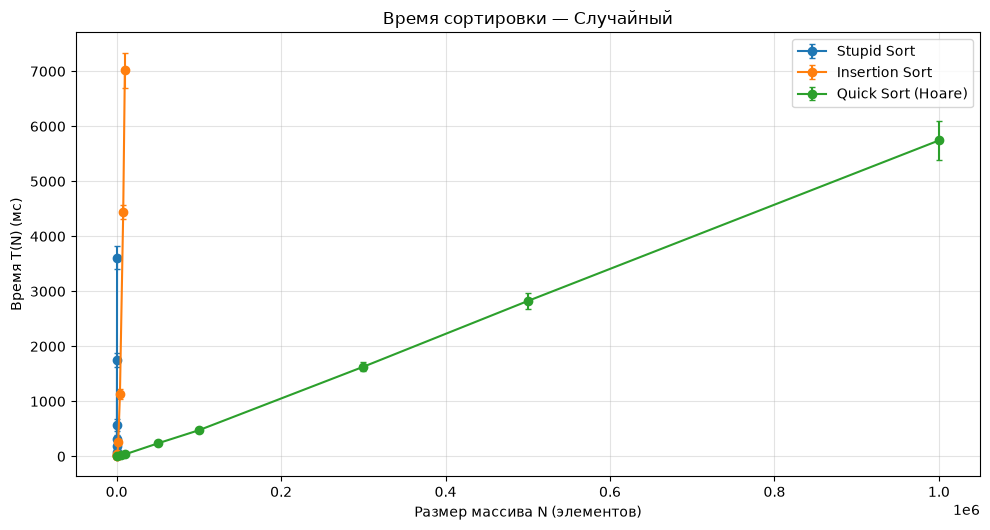

In [8]:
fig = plot_time(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()

## 9. График 2: двойной логарифмический масштаб (Log-Log)

Если время подчиняется степенной зависимости $T(N) = cN^k$, то $\log T(N) = k\log N + \log c$. На Log-Log графике получается почти прямая, её наклон равен показателю $k$.

Ожидания на типичных больших наборах: Stupid Sort (случайный/обратный) — около 3; Insertion Sort (случайный/обратный) — около 2; QuickSort — около 1–1.15. Для отсортированного списка Stupid и Insertion растут примерно как $N^1$. Реальные наклоны могут отличаться: они зависят от набора размеров, шума замеров и поведения Python.

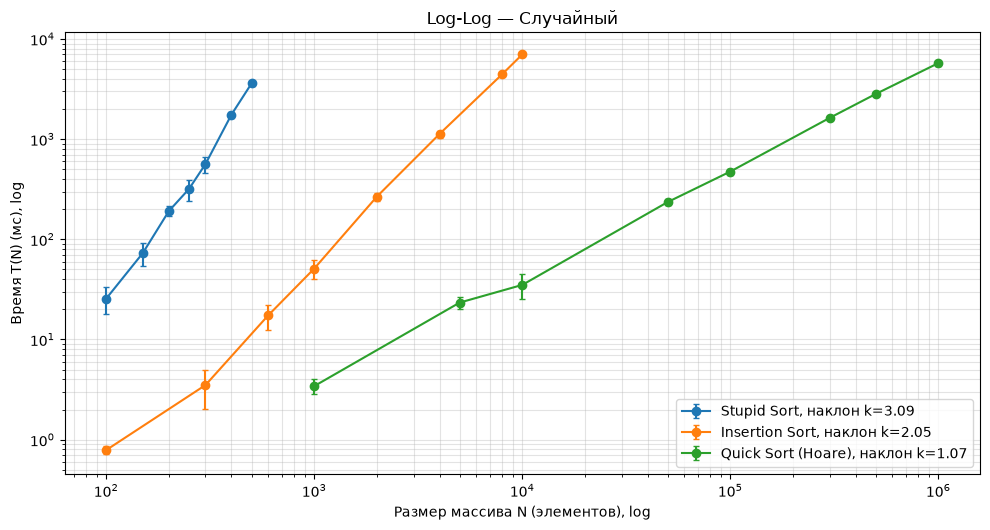

Наклоны Log-Log по реальным измерениям:
Stupid Sort: 3.086
Insertion Sort: 2.052
Quick Sort (Hoare): 1.073


In [9]:
fig, slopes = plot_loglog(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()
print("Наклоны Log-Log по реальным измерениям:")
for name, slope in slopes.items():
    print(f"{name}: {slope:.3f}" if slope is not None else name + ": мало точек")

## 10. График 3: теоретическая аппроксимация (fitting)

Экспериментальные времена изображаются точками, теоретическая зависимость — плавной линией. Принцип: $T(N) \approx c f(N)$, где $f(N)$ — $N$, $N^2$, $N^3$ или $N\log_2N$. Коэффициент $c$ подбираем **методом наименьших квадратов** (МНК):

$$c = \frac{\sum_i f(N_i)\,T_i}{\sum_i f(N_i)^2}.$$

Функция `fit_coefficient` вычисляет эту формулу. Это **подгонка коэффициента**, а не доказательство математической сложности. Теория задаёт ожидаемую форму зависимости.

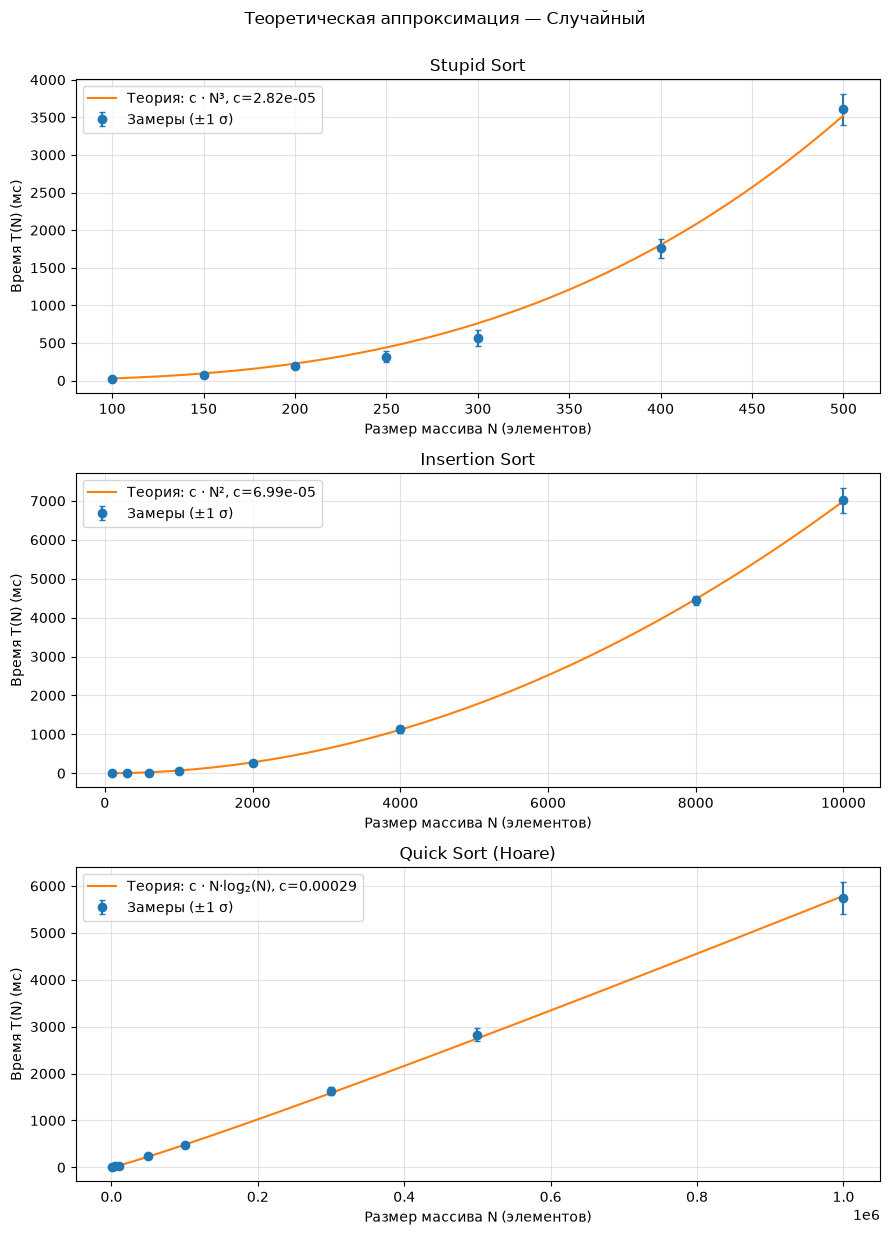

Stupid Sort: модель c · N³; подобранный коэффициент с = 2.82e-05
Insertion Sort: модель c · N²; подобранный коэффициент с = 6.9934e-05
Quick Sort (Hoare): модель c · N·log₂(N); подобранный коэффициент с = 0.00029046


In [10]:
fig, coefficients = plot_fitting(summary_rows, CHOSEN_DISTRIBUTION)
plt.show()
for name, (model, coefficient) in coefficients.items():
    print(f"{name}: модель {model}; подобранный коэффициент с = {coefficient:.5g}")

## 11. Сравнение всех пяти распределений

Для каждого типа входных данных ниже строится компактная пара графиков: линейный и Log-Log, чтобы проверить изменение поведения. Это также помогает заметить, что почти отсортированные входы для Insertion Sort обычно выгоднее случайных, а обратный порядок хуже.


 СЛУЧАЙНЫЙ


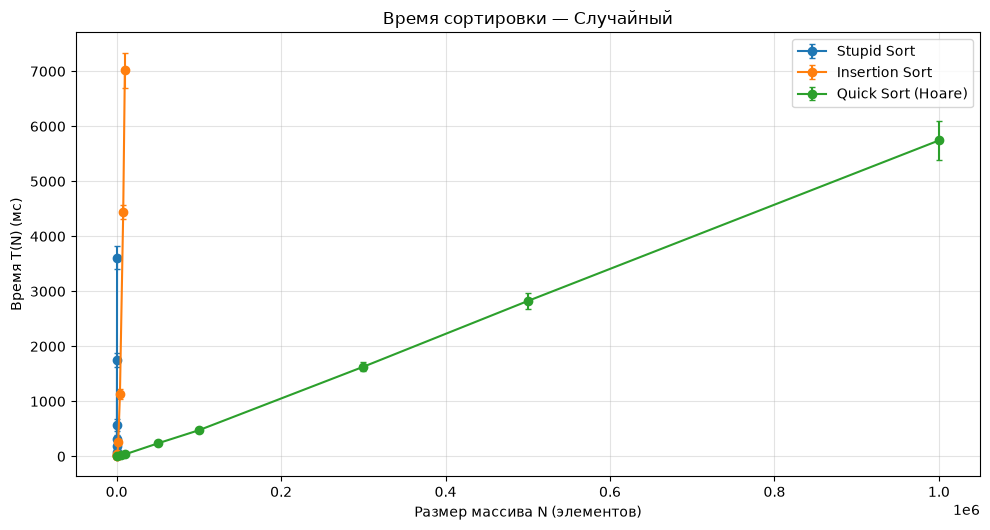

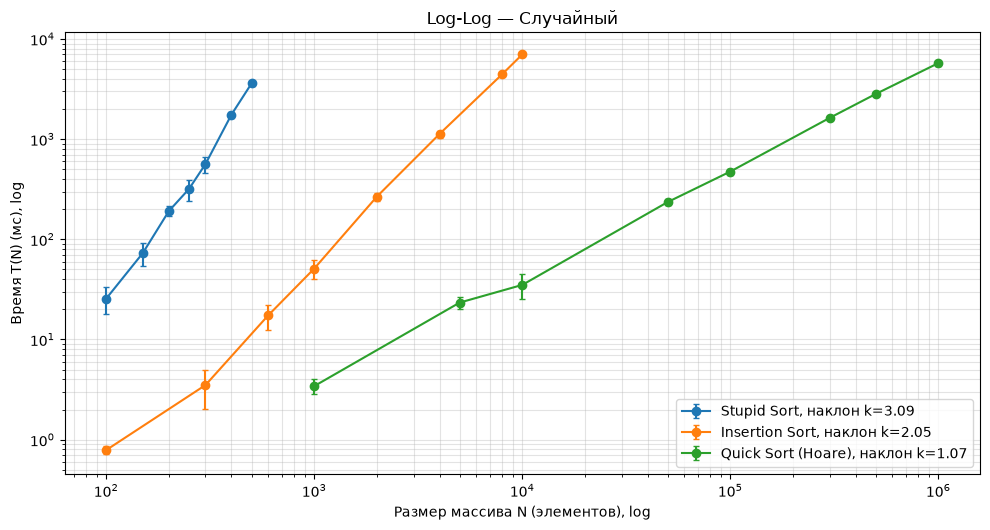

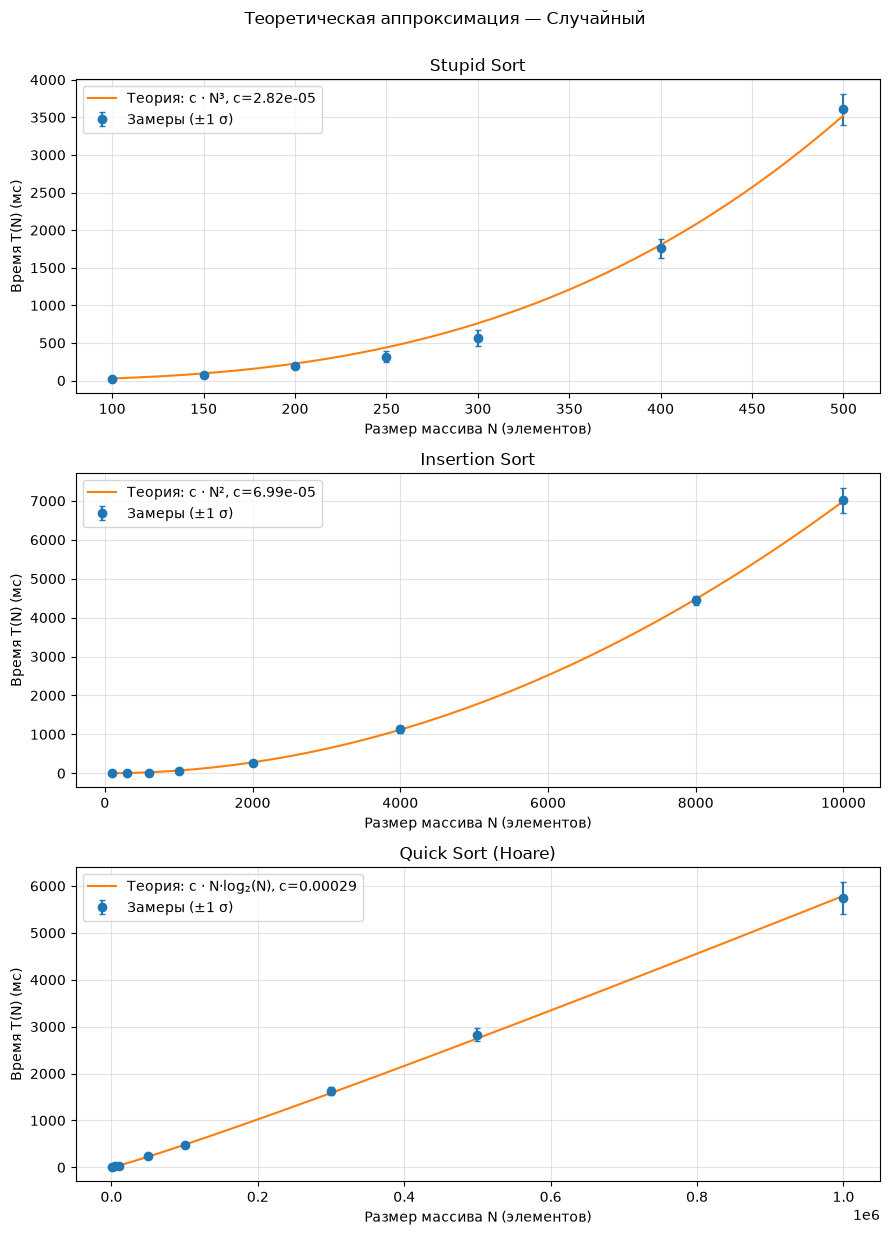

Оценки наклона: {'Stupid Sort': 3.086, 'Insertion Sort': 2.052, 'Quick Sort (Hoare)': 1.073}

 ОТСОРТИРОВАННЫЙ


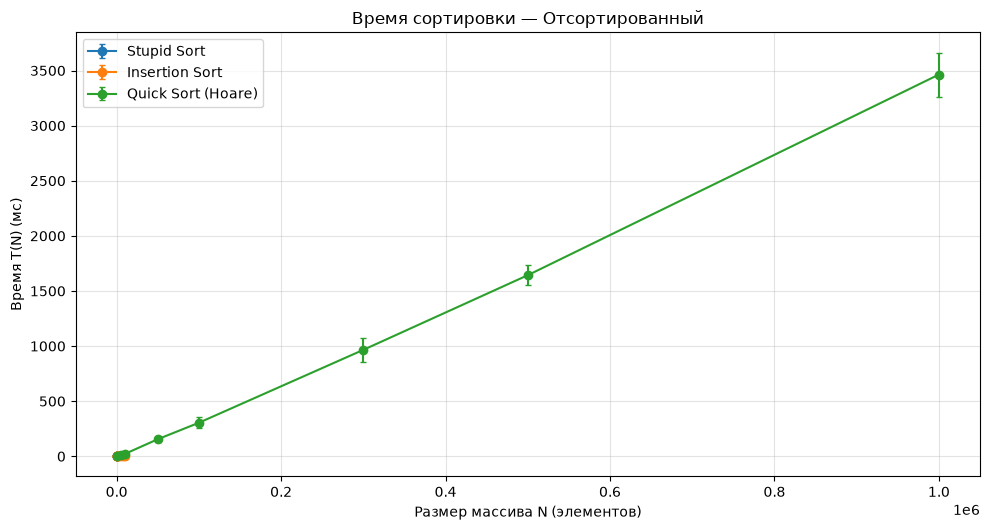

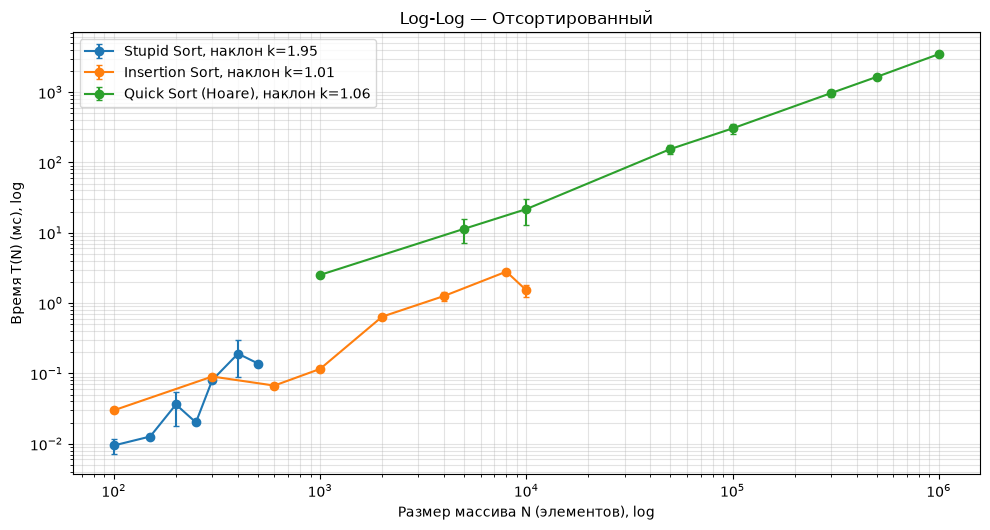

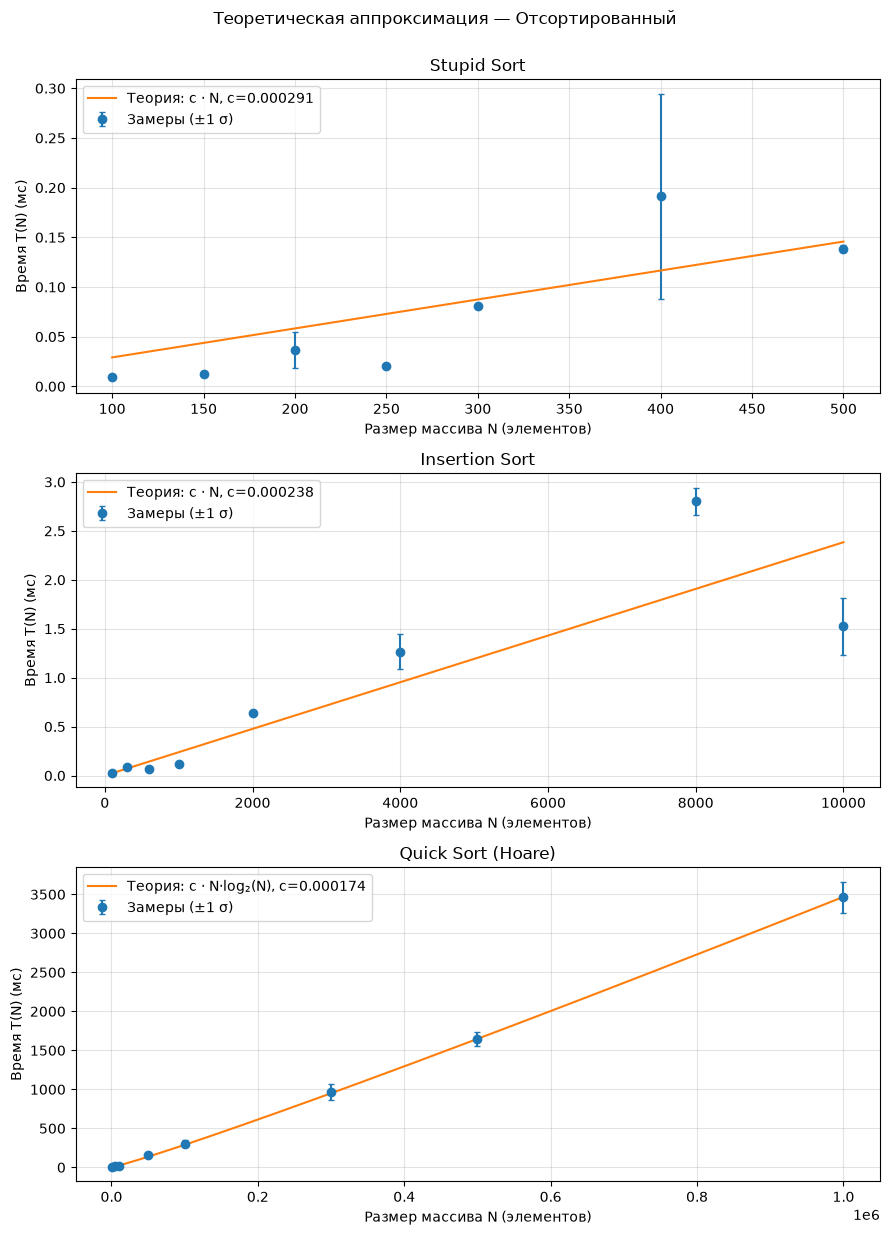

Оценки наклона: {'Stupid Sort': 1.954, 'Insertion Sort': 1.005, 'Quick Sort (Hoare)': 1.064}

 ОБРАТНО ОТСОРТИРОВАННЫЙ


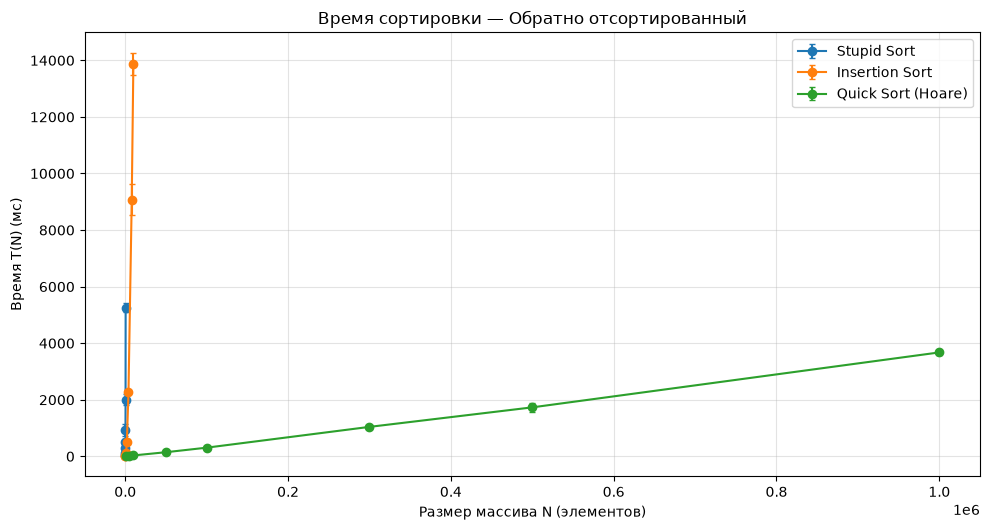

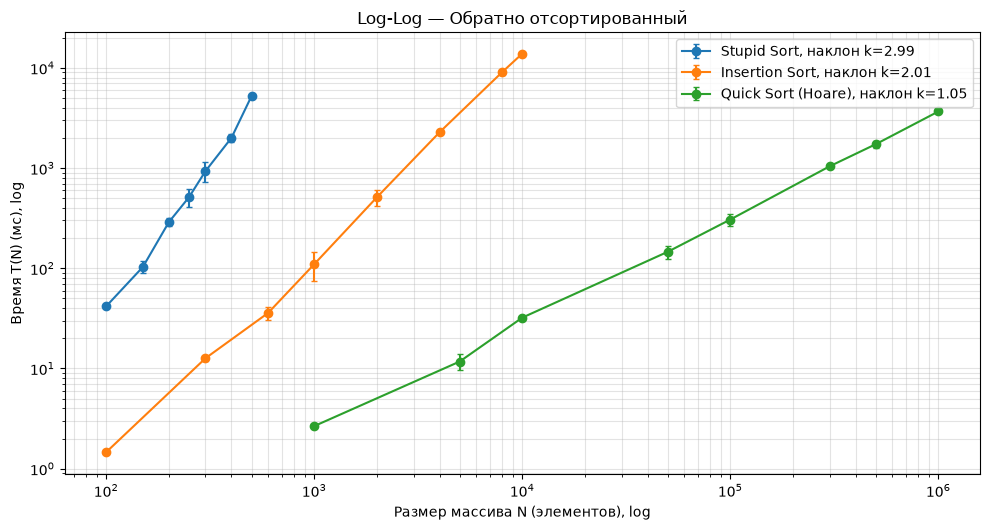

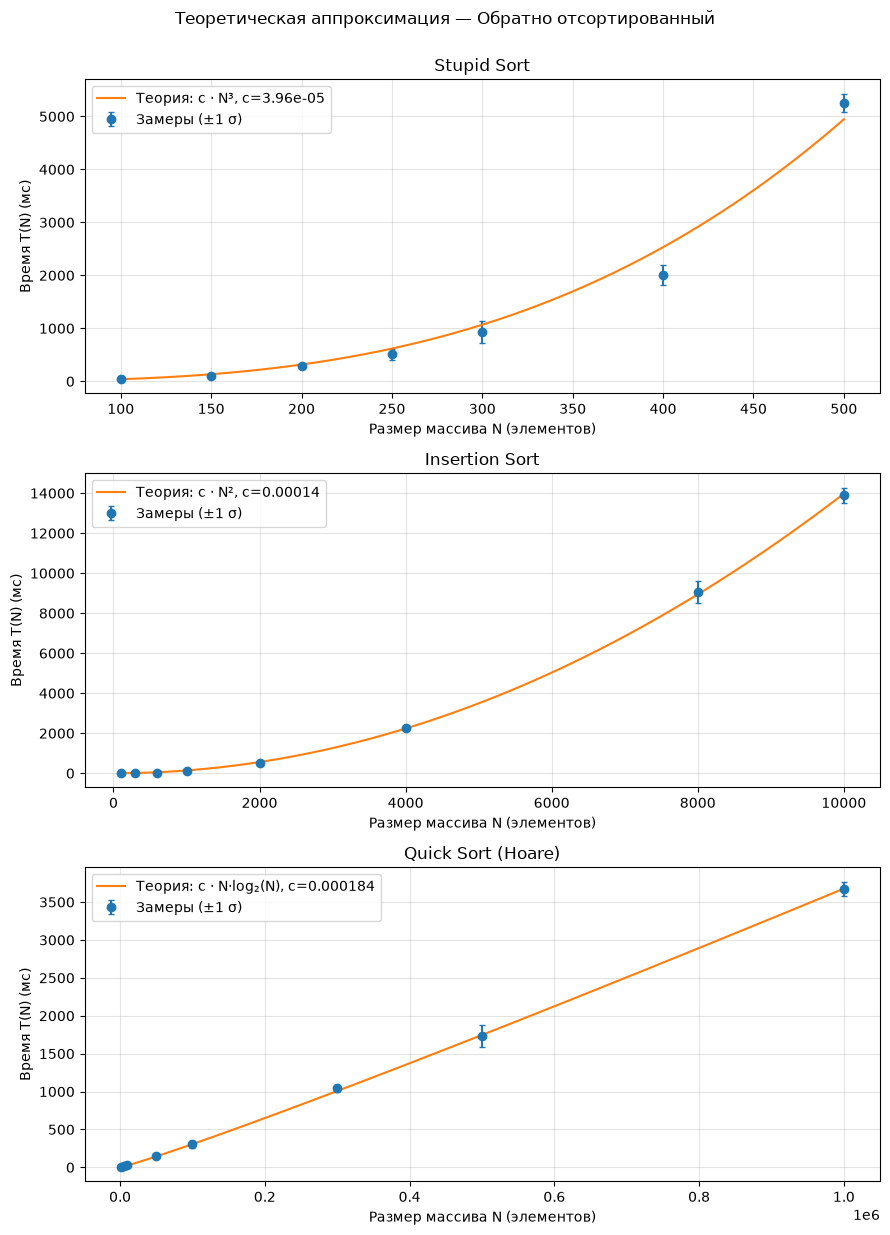

Оценки наклона: {'Stupid Sort': 2.987, 'Insertion Sort': 2.012, 'Quick Sort (Hoare)': 1.052}

 ПОЧТИ ОТСОРТИРОВАННЫЙ


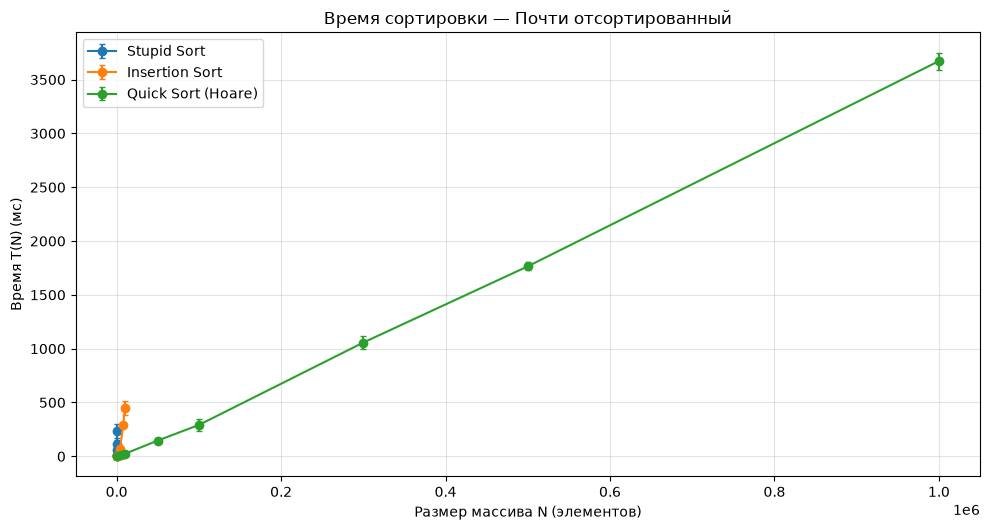

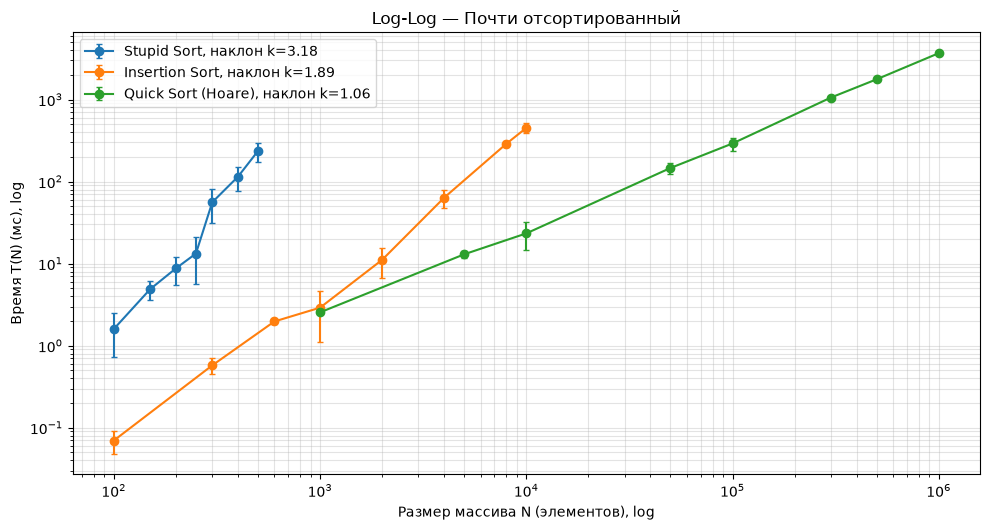

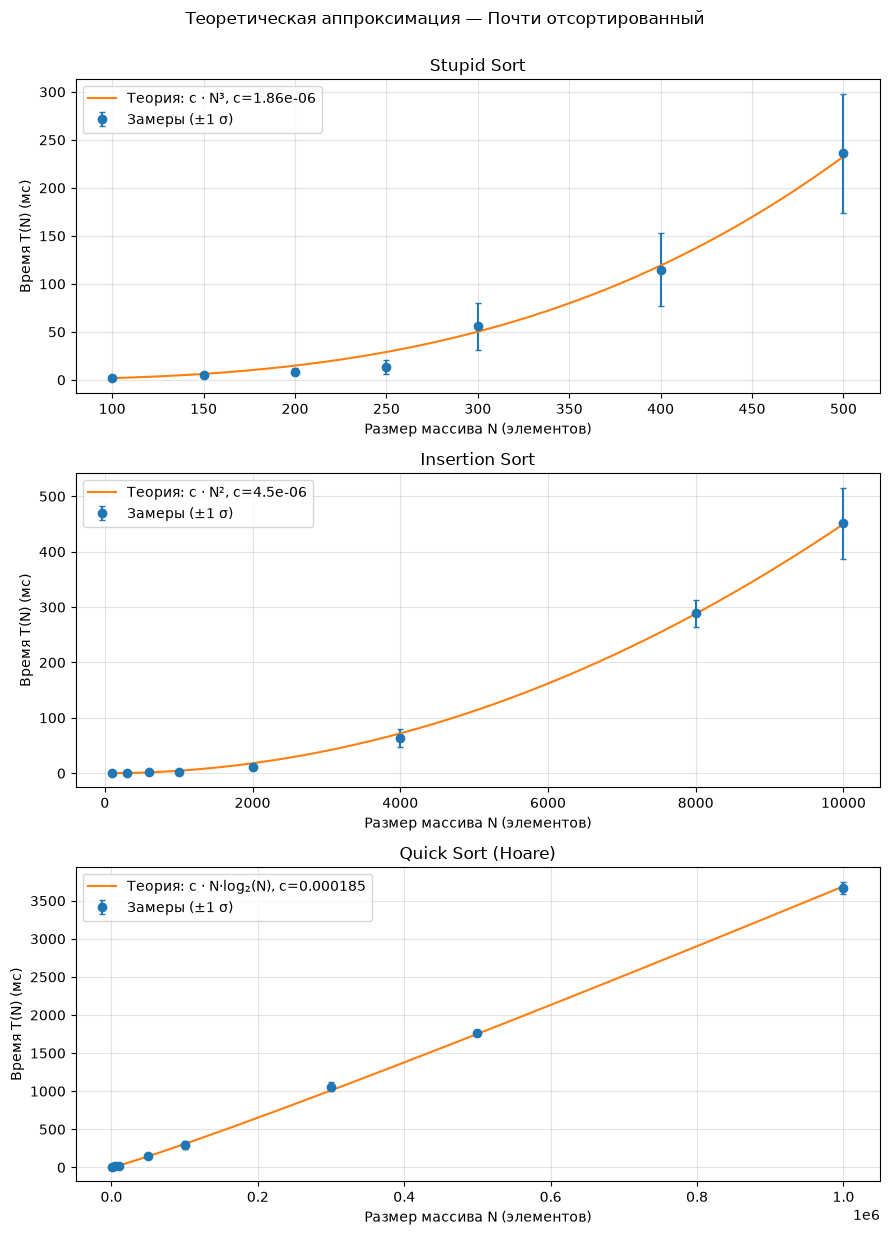

Оценки наклона: {'Stupid Sort': 3.175, 'Insertion Sort': 1.89, 'Quick Sort (Hoare)': 1.064}

 МНОГО ПОВТОРЕНИЙ


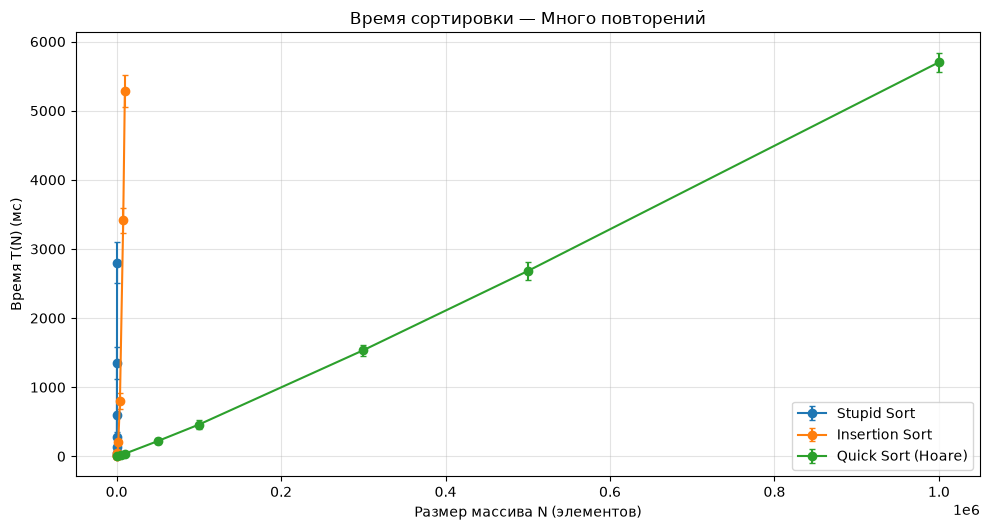

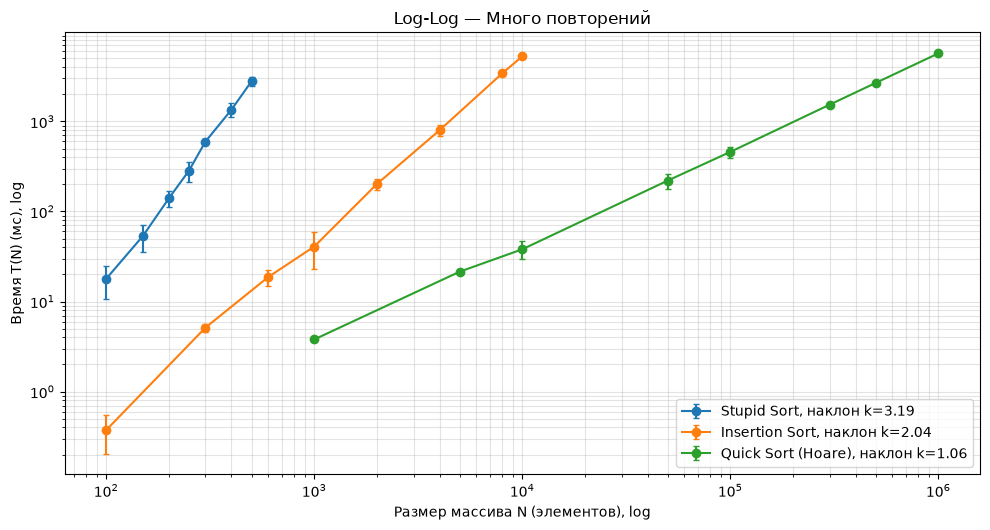

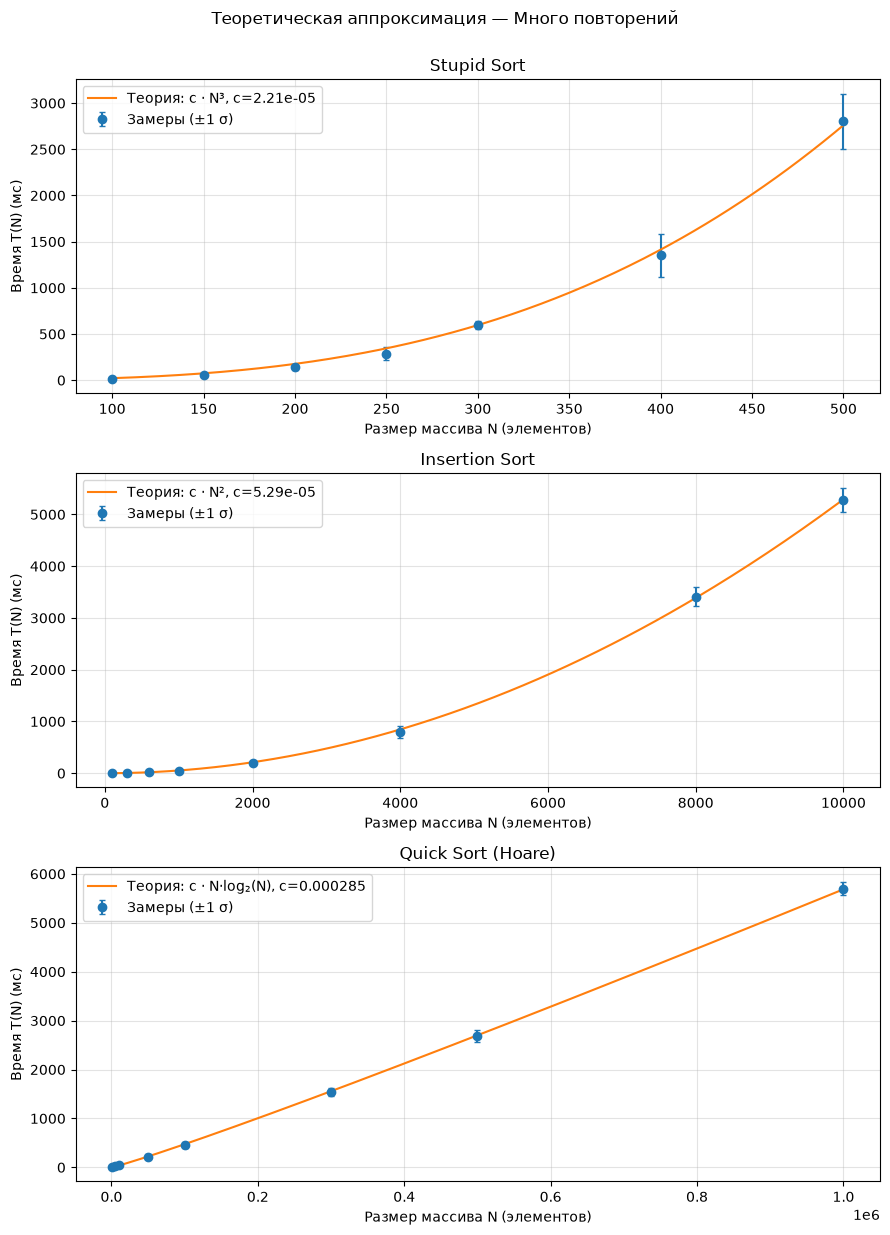

Оценки наклона: {'Stupid Sort': 3.192, 'Insertion Sort': 2.044, 'Quick Sort (Hoare)': 1.058}


In [11]:
for kind in DISTRIBUTIONS:
    print("\n", DISTRIBUTIONS[kind].upper())
    fig = plot_time(summary_rows, kind)
    plt.show()
    fig, current_slopes = plot_loglog(summary_rows, kind)
    plt.show()
    fig, _ = plot_fitting(summary_rows, kind)
    plt.show()
    print("Оценки наклона:", {name: round(k, 3) if k is not None else None
                                for name, k in current_slopes.items()})

## 12. Какой алгоритм использовал меньше сравнений?

Сравнивать нужно **на одинаковом размере и типе входного массива**. Сетки из ТЗ различаются, поэтому на финальном большом графике не всегда есть общие размеры. Ниже для ориентировочного сравнения выведены значения на пересекающихся N.

In [12]:
comparison_table = summary_df[["algorithm", "distribution", "n", "mean_comparisons"]].copy()
display(comparison_table.head(25))

,algorithm,distribution,n,mean_comparisons
0,Stupid Sort,random,100,114421.4
1,Stupid Sort,sorted,100,99.0
2,Stupid Sort,reversed,100,166749.0
3,Stupid Sort,nearly_sorted,100,6346.6
4,Stupid Sort,duplicates,100,94757.4
5,Stupid Sort,random,150,363700.4
6,Stupid Sort,sorted,150,149.0
7,Stupid Sort,reversed,150,562624.0
8,Stupid Sort,nearly_sorted,150,19784.6
9,Stupid Sort,duplicates,150,306971.0


In [17]:
final_table = (
    summary_df
    .sort_values("n")
    .groupby(["algorithm", "distribution"], as_index=False)
    .tail(1)
)

display(
    final_table[
        ["algorithm", "distribution", "n",
         "mean_ms", "std_ms", "mean_comparisons"]
    ].sort_values(["distribution", "algorithm"])
)

,algorithm,distribution,n,mean_ms,std_ms,mean_comparisons
74,Insertion Sort,duplicates,10000,5282.44046,235.139401,19971531.4
114,Quick Sort (Hoare),duplicates,1000000,5701.11574,141.104220,22295376.6
34,Stupid Sort,duplicates,500,2803.00610,299.878349,11330571.0
73,Insertion Sort,nearly_sorted,10000,451.04054,64.639580,1657473.0
113,Quick Sort (Hoare),nearly_sorted,1000000,3672.05018,79.435242,21134070.6
33,Stupid Sort,nearly_sorted,500,236.05450,62.150743,1016656.6
70,Insertion Sort,random,10000,7014.62324,326.382084,24943143.8
110,Quick Sort (Hoare),random,1000000,5742.42724,350.142212,28047152.0
30,Stupid Sort,random,500,3609.86532,205.629588,13913827.4
72,Insertion Sort,reversed,10000,13885.47238,391.131594,49995000.0


In [16]:
# Дополнительное сравнение при одинаковом N

comparison_raw, comparison_summary = benchmark(
    names=list(SORTS),
    distributions=list(DISTRIBUTIONS),
    sizes={name: [100] for name in SORTS},
    repeats=REPEATS,
    progress=print
)

comparison_df = pd.DataFrame(comparison_summary)

display(
    comparison_df[
        ["distribution", "algorithm", "n",
         "mean_ms", "std_ms", "mean_comparisons"]
    ].sort_values(["distribution", "mean_ms"])
)

save_csv(comparison_raw, "results/comparison_n100_raw.csv")
save_csv(comparison_summary, "results/comparison_n100_summary.csv")

print("Сравнение при N = 100 сохранено.")

Stupid Sort, Случайный, N=100: готово
Stupid Sort, Отсортированный, N=100: готово
Stupid Sort, Обратно отсортированный, N=100: готово
Stupid Sort, Почти отсортированный, N=100: готово
Stupid Sort, Много повторений, N=100: готово
Insertion Sort, Случайный, N=100: готово
Insertion Sort, Отсортированный, N=100: готово
Insertion Sort, Обратно отсортированный, N=100: готово
Insertion Sort, Почти отсортированный, N=100: готово
Insertion Sort, Много повторений, N=100: готово
Quick Sort (Hoare), Случайный, N=100: готово
Quick Sort (Hoare), Отсортированный, N=100: готово
Quick Sort (Hoare), Обратно отсортированный, N=100: готово
Quick Sort (Hoare), Почти отсортированный, N=100: готово
Quick Sort (Hoare), Много повторений, N=100: готово


,distribution,algorithm,n,mean_ms,std_ms,mean_comparisons
14,duplicates,Quick Sort (Hoare),100,0.27118,0.036810,892.0
9,duplicates,Insertion Sort,100,0.61754,0.039166,2149.2
4,duplicates,Stupid Sort,100,17.77090,8.007603,94757.4
8,nearly_sorted,Insertion Sort,100,0.06980,0.022023,226.6
13,nearly_sorted,Quick Sort (Hoare),100,0.17814,0.001295,771.6
3,nearly_sorted,Stupid Sort,100,1.63344,0.881024,6346.6
10,random,Quick Sort (Hoare),100,0.25228,0.009743,985.8
5,random,Insertion Sort,100,0.77124,0.051570,2677.6
0,random,Stupid Sort,100,29.90640,3.565974,114421.4
12,reversed,Quick Sort (Hoare),100,0.18800,0.000975,772.0


Сравнение при N = 100 сохранено.


## 13. Опциональный бонус: дополнительная память

`tracemalloc` запускается **после создания входного списка**, поэтому здесь измеряется пик дополнительных Python-выделений, а не полная память процесса. Алгоритмы используют разные диапазоны размеров N. В теоретической модели дополнительная память Stupid Sort и Insertion Sort составляет $O(1)$, а типичная глубина рекурсии QuickSort — $O(\log N)$ (худший случай — $O(N)$).

,algorithm,distribution,n,peak_kib
0,Stupid Sort,random,20,0.062500
1,Stupid Sort,random,50,0.093750
2,Stupid Sort,random,100,0.745117
3,Stupid Sort,random,200,0.093750
4,Insertion Sort,random,100,0.125000
5,Insertion Sort,random,1000,0.187500
6,Insertion Sort,random,3000,1.062500
7,Insertion Sort,random,5000,1.796875
8,Quick Sort (Hoare),random,1000,1.539062
9,Quick Sort (Hoare),random,3000,2.000000


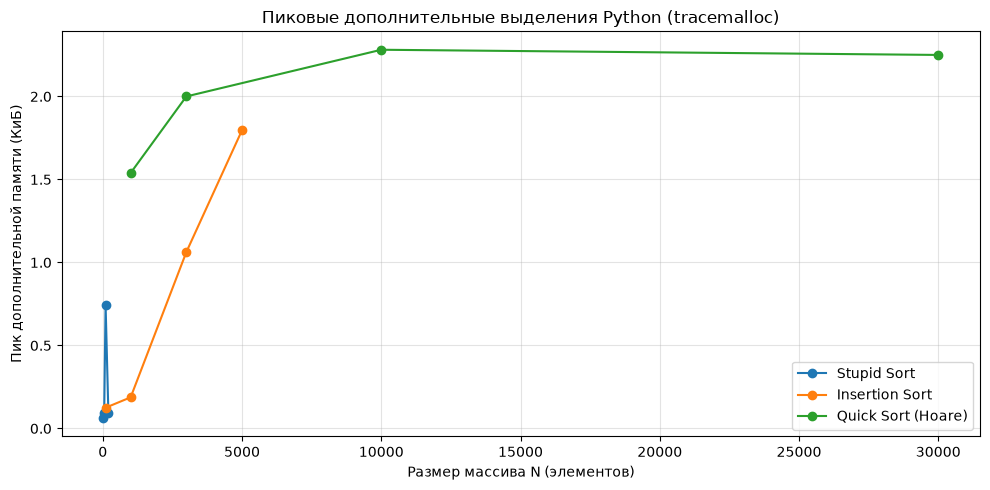

In [15]:
memory_rows = memory_profile()
display(pd.DataFrame(memory_rows))
fig = plot_memory(memory_rows)
plt.show()

## 14. Личный аналитический вывод

Кто оказался быстрее на почти отсортированных данных?

В дополнительном эксперименте при одинаковом размере массива N = 100 наименьшее среднее время показал Insertion Sort — 0,06980 мс. Quick Sort (Hoare) потребовал 0,17814 мс, а Stupid Sort — 1,63344 мс. Для сравнения, на случайном массиве того же размера время Insertion Sort составляло 0,77124 мс. Это объясняется тем, что на почти отсортированных данных сортировке вставками требуется значительно меньше сдвигов элементов. Однако преимущество установлено для N = 100: на больших массивах результаты необходимо анализировать отдельно.

Кто делал меньше всего сравнений при одинаковом N и типе массива?

Результат зависит от распределения элементов. При N = 100 на случайном массиве наименьшее среднее число сравнений показал Quick Sort — 985,8. Insertion Sort выполнил 2677,6 сравнений, а Stupid Sort — 114421,4. На почти отсортированном массиве лидировал Insertion Sort — 226,6 сравнения против 771,6 у Quick Sort и 6346,6 у Stupid Sort. На полностью отсортированном массиве Insertion Sort и Stupid Sort выполнили по 99 сравнений. Следовательно, алгоритма с минимальным числом сравнений для всех типов входных данных не обнаружено.

Каковы реальные наклоны Log-Log?

Для случайных массивов экспериментальные наклоны составили: Stupid Sort — 3,086, Insertion Sort — 2,052, Quick Sort — 1,073. На обратно отсортированных массивах получились соответственно 2,987, 2,012 и 1,052. Эти результаты согласуются с ожидаемым кубическим ростом Stupid Sort, квадратичным ростом Insertion Sort и зависимостью порядка N log N для Quick Sort. На полностью отсортированных массивах наклон Insertion Sort снизился до 1,005, что соответствует почти линейному времени. Отклонения от теоретических значений могут быть вызваны ограниченным диапазоном размеров N, фоновыми процессами и накладными расходами Python. Для Stupid Sort на отсортированных данных наклон времени составил 1,954, хотя число сравнений растёт линейно; это расхождение показывает ограничения оценки асимптотики по измерениям времени.

Совпала ли подгонка с замерами?

Для случайных массивов использовались теоретические модели c·N³ для Stupid Sort, c·N² для Insertion Sort и c·N·log₂(N) для Quick Sort. Подобранные методом наименьших квадратов коэффициенты составили соответственно 2,82·10⁻⁵, 6,9934·10⁻⁵ и 2,9046·10⁻⁴. На графиках экспериментальные точки в целом располагаются близко к теоретическим кривым, особенно для Insertion Sort и Quick Sort. У Stupid Sort заметны отдельные отклонения, в частности при промежуточных размерах массивов. Таким образом, выбранные модели достаточно хорошо описывают общий рост времени, но не воспроизводят каждое измерение точно. На почти отсортированных данных расхождения могут быть сильнее, поскольку фактическая работа алгоритмов зависит от исходного порядка элементов.

Какая дополнительная память понадобилась?

Измерения проводились с помощью tracemalloc, который отслеживает дополнительные выделения памяти Python во время сортировки. Например, для Quick Sort при N = 30000 пиковое значение составило 2,250 КиБ, а для Insertion Sort при N = 5000 — 1,797 КиБ. Для Stupid Sort при N = 200 было зарегистрировано 0,094 КиБ. В теории Stupid Sort и Insertion Sort используют O(1) дополнительной алгоритмической памяти, поскольку работают с небольшим числом вспомогательных переменных. Quick Sort дополнительно использует стек рекурсивных вызовов, обычно порядка O(log N) при сбалансированных разбиениях. Измерения tracemalloc не отражают полностью всю память процесса и не позволяют строго доказать эти асимптотические оценки.

Почему результаты разных распределений отличаются?

Разные типы массивов приводят к различному количеству сравнений, обменов и записей. На полностью отсортированных данных Stupid Sort не выполняет обменов, а Insertion Sort практически не сдвигает элементы, поэтому оба алгоритма работают быстро. На обратно отсортированных массивах требуется гораздо больше перемещений, что увеличивает время работы. Почти отсортированные массивы выгодны для Insertion Sort, поскольку большинство элементов уже находится близко к правильному положению. Quick Sort менее чувствителен к исходному порядку на исследованных наборах данных благодаря рекурсивному разбиению массива, хотя конкретная эффективность также зависит от расположения опорных элементов и наличия повторяющихся значений.

Заключение: Проведённый эксперимент показал существенное различие в скорости роста времени трёх алгоритмов сортировки. На случайных и обратно отсортированных массивах наклоны Log-Log оказались близки к ожидаемым теоретическим зависимостям. При небольшом размере и почти отсортированных данных наилучшее время показал Insertion Sort, тогда как Quick Sort продемонстрировал преимущество при обработке больших случайных массивов. Не все измерения точно совпали с теоретическими моделями, что объясняется особенностями входных данных, ограниченностью экспериментальных размеров и погрешностями измерения времени.
## Источники

- Индивидуальное ТЗ кафедры (файл пользователя).
- [Сортировки, материалы курса ФБМФ МФТИ](https://cs.mipt.ru/fbmf/lessons/sem_1/08.sorts.html).
- Python: `time.perf_counter`, `statistics`, `tracemalloc` (стандартная библиотека).
- `matplotlib` / `numpy`: построение графиков и оценка наклона.